# Telecom Customer Churn Prediction

**End-to-end machine learning case study | IBM Telco Customer Churn**

This notebook documents data cleaning, exploratory analysis, initial model experiments, a revised train/validation/test evaluation, threshold selection, and model export for a [deployed Streamlit application](https://telecom-customer-churn-prediction-g3vbghivucmfk47mxbcxxz.streamlit.app/).

**Objective:** Estimate the probability that a telecom customer will churn using customer account and service attributes. This is an educational demonstration, not a production-ready retention system.

**Workflow:** Load → clean → explore → compare models → revise evaluation design → select threshold on validation data → evaluate on test data → export model.

## 1. Load and inspect the data

The notebook reads the public IBM Telco Customer Churn dataset. The target variable is `Churn` (`Yes`/`No`). Customer IDs are excluded from the predictive features.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

print(df.isnull().sum())

print(df["Churn"].value_counts())

print(df["Churn"].value_counts(normalize=True) * 100)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Clean the dataset

Convert `TotalCharges` to numeric, coercing invalid entries to missing values, and remove rows where it cannot be recovered. The cleaned dataset contains **7,032 customers**.

In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)


print(df["TotalCharges"].isnull().sum())


df = df.dropna(subset=["TotalCharges"]).copy()

print("Cleaned dataset:", df.shape)


11
Cleaned dataset: (7032, 21)


## 3. Exploratory data analysis

Explore churn rates by contract type, and compare monthly charges and tenure across churn groups. These are descriptive associations; they do **not** establish causation.

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


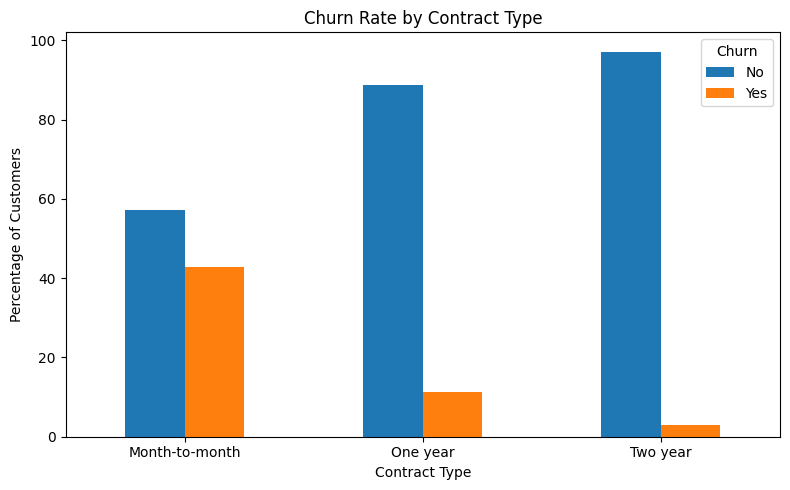

In [4]:

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.ylabel("Percentage of Customers")
plt.xlabel("Contract Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


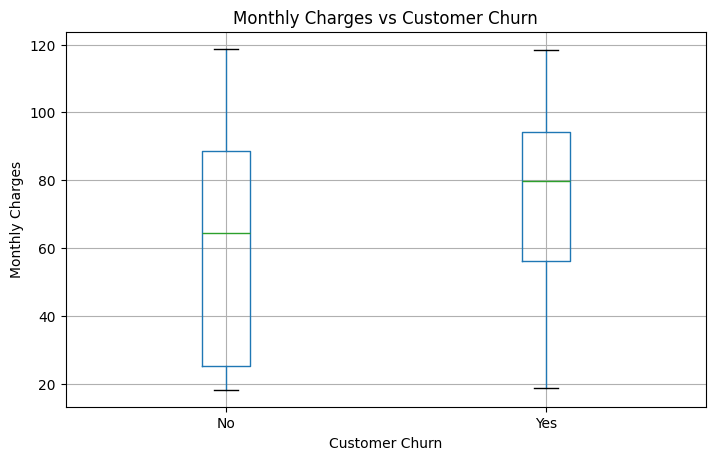

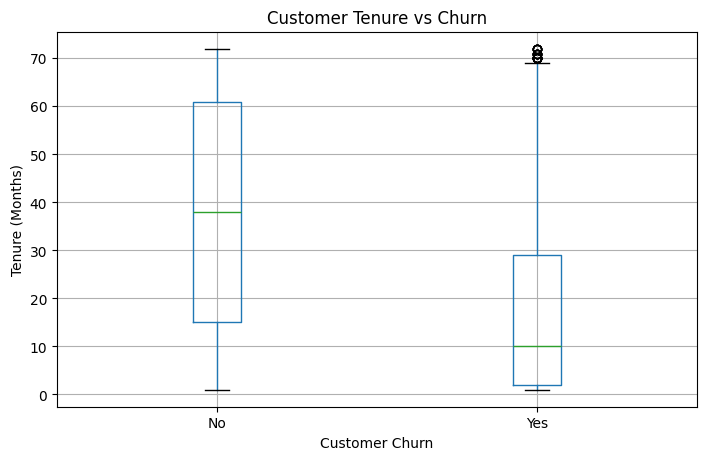

In [5]:

import matplotlib.pyplot as plt

df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(8, 5)
)

plt.title("Monthly Charges vs Customer Churn")
plt.suptitle("")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.show()

df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(8, 5)
)

plt.title("Customer Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.show()


## 4. Initial model experiments (exploratory)

The first experiment uses an **80/20 stratified train/test split** to compare Logistic Regression and Random Forest. Numeric variables are imputed and scaled; categorical variables are imputed and one-hot encoded using a scikit-learn pipeline.

**Important:** The early holdout data are used for exploratory analysis, including permutation importance and inspection of an adjusted threshold. Consequently, these early results should **not** be presented as the project's final independent test evaluation. The revised protocol begins in Section 6.

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn", "customerID"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))


Training customers: 5625
Testing customers: 1407


In [7]:

numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [8]:

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC Score:")
print(round(roc_auc_score(y_test, y_prob), 4))


Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

Confusion Matrix:
[[917 116]
 [160 214]]
ROC-AUC Score:
0.8359


In [9]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results:")
print(classification_report(y_test, rf_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))


Random Forest Results:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.62      0.47      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.70      1407
weighted avg       0.77      0.78      0.77      1407

Confusion Matrix:
[[926 107]
 [197 177]]
ROC-AUC: 0.8120395918642033


In [10]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(results.round(4))



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8038,0.6485,0.5722,0.608,0.8359
1,Random Forest,0.7839,0.6232,0.4733,0.538,0.8120


### 4.1 Preliminary cross-validated threshold exploration

Out-of-fold probabilities from the initial training partition are used to inspect the precision–recall trade-off at candidate thresholds. The following optimized predictions on the initial test partition are **exploratory only**.

In [11]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_prob = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (train_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1": f1_score(y_train, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1
0,0.30,0.5418,0.7666,0.6349
1,0.35,0.5651,0.7171,0.6321
2,0.40,0.5921,0.6582,0.6234
3,0.45,0.6118,0.5987,0.6051
4,0.50,0.6536,0.5465,0.5953


In [12]:

best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Best Threshold:", best_threshold)
print("CV Precision:", round(best_row["Precision"], 4))
print("CV Recall:", round(best_row["Recall"], 4))
print("CV F1:", round(best_row["F1"], 4))


Best Threshold: 0.3
CV Precision: 0.5418
CV Recall: 0.7666
CV F1: 0.6349


In [13]:

from sklearn.metrics import classification_report, confusion_matrix

optimized_pred = (y_prob >= best_threshold).astype(int)

print("Optimized Logistic Regression:")
print(classification_report(y_test, optimized_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, optimized_pred))



Optimized Logistic Regression:
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1033
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407

Confusion Matrix:
[[761 272]
 [ 90 284]]


## 5. Exploratory model interpretation

Permutation importance measures how shuffling a raw feature changes ROC-AUC on the **initial exploratory holdout**. Logistic Regression coefficients describe model associations after preprocessing; they should not be interpreted as causal effects. Because this analysis inspects the earlier holdout, it is not an untouched independent explanation sample.

,Feature,Importance,Std
4,tenure,0.191048,0.016757
7,InternetService,0.044064,0.005093
14,Contract,0.033548,0.007575
17,MonthlyCharges,0.023138,0.004414
18,TotalCharges,0.021481,0.004839
15,PaperlessBilling,0.004196,0.001762
12,StreamingTV,0.003355,0.001702
13,StreamingMovies,0.003144,0.002385
11,TechSupport,0.003038,0.002417
16,PaymentMethod,0.002869,0.001870


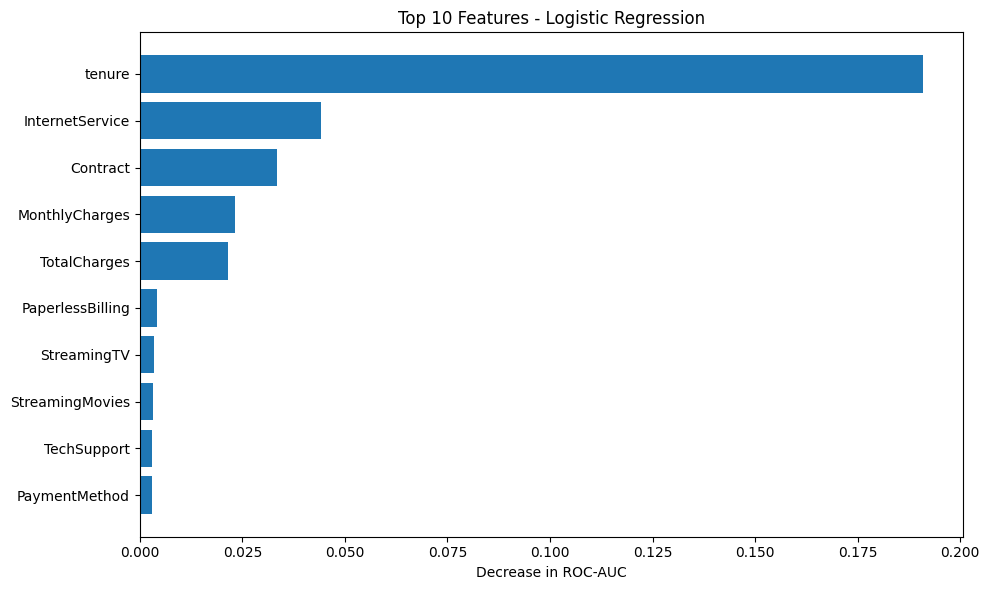

In [14]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# قياس أهمية المتغيرات على بيانات الاختبار
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(feature_importance.head(10))

# رسم أهم 10 متغيرات
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Decrease in ROC-AUC")
plt.title("Top 10 Features - Logistic Regression")
plt.tight_layout()
plt.show()


,Feature,Coefficient,Absolute
1,num__tenure,-1.352313,1.352313
38,cat__Contract_Two year,-0.779030,0.779030
3,num__TotalCharges,0.644014,0.644014
15,cat__InternetService_DSL,-0.616132,0.616132
36,cat__Contract_Month-to-month,0.613846,0.613846
16,cat__InternetService_Fiber optic,0.590184,0.590184
2,num__MonthlyCharges,-0.541006,0.541006
39,cat__PaperlessBilling_No,-0.300387,0.300387
12,cat__MultipleLines_No,-0.293470,0.293470
17,cat__InternetService_No,-0.283724,0.283724


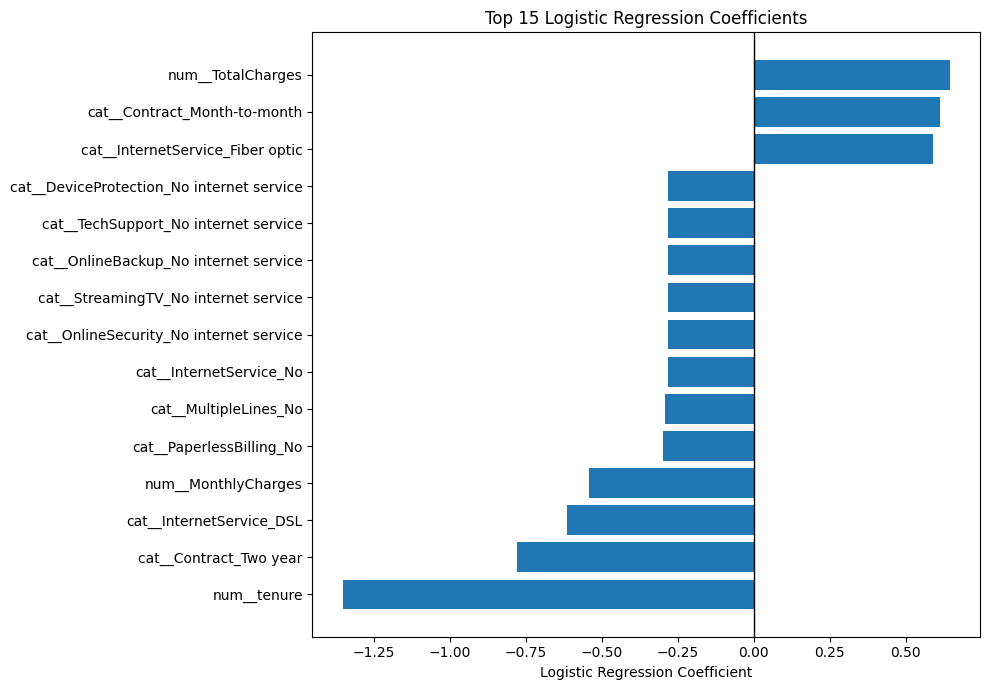

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "classifier"
].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute"] = coef_df[
    "Coefficient"
].abs()

coef_df = coef_df.sort_values(
    "Absolute",
    ascending=False
)

display(coef_df.head(15))

top = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top["Feature"],
    top["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()


## 6. Revised evaluation: stratified 60/20/20 split

A second experiment uses **60% training (4,219), 20% validation (1,406), and 20% test (1,407)**. Both models are refitted on the new training partition. Model comparison and decision-threshold selection use the validation partition; the revised test partition is evaluated only after selecting the threshold.

**Caveat:** Because this revision followed earlier experiments on the same underlying dataset, it is more disciplined than the initial split but **not fully independent of prior exploratory decisions**. External or time-based validation would be needed to establish deployment generalizability.

In [16]:

from sklearn.model_selection import train_test_split

X_final = df.drop(columns=["Churn", "customerID"])
y_final = df["Churn"].map({"No": 0, "Yes": 1})

X_train_new, X_temp, y_train_new, y_temp = train_test_split(
    X_final,
    y_final,
    test_size=0.40,
    random_state=123,
    stratify=y_final
)

X_val, X_test_new, y_val, y_test_new = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=123,
    stratify=y_temp
)

print("Training:", len(X_train_new))
print("Validation:", len(X_val))
print("Test:", len(X_test_new))



Training: 4219
Validation: 1406
Test: 1407


### 6.1 Compare Logistic Regression and Random Forest

Compare validation accuracy, precision, recall, F1, and ROC-AUC at the default threshold of 0.50. Logistic Regression is selected for the final evaluation.

In [17]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

lr_final = clone(model)
rf_final = clone(rf_model)

lr_final.fit(X_train_new, y_train_new)
rf_final.fit(X_train_new, y_train_new)

lr_val_prob = lr_final.predict_proba(X_val)[:, 1]
rf_val_prob = rf_final.predict_proba(X_val)[:, 1]

lr_val_pred = (lr_val_prob >= 0.50).astype(int)
rf_val_pred = (rf_val_prob >= 0.50).astype(int)

validation_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_val, lr_val_pred),
        accuracy_score(y_val, rf_val_pred)
    ],
    "Precision": [
        precision_score(y_val, lr_val_pred),
        precision_score(y_val, rf_val_pred)
    ],
    "Recall": [
        recall_score(y_val, lr_val_pred),
        recall_score(y_val, rf_val_pred)
    ],
    "F1": [
        f1_score(y_val, lr_val_pred),
        f1_score(y_val, rf_val_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, lr_val_prob),
        roc_auc_score(y_val, rf_val_prob)
    ]
})

display(validation_results.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7980,0.6389,0.5535,0.5931,0.8388
1,Random Forest,0.7838,0.6250,0.4679,0.5352,0.8221


### 6.2 Select the decision threshold on validation data

Sweep candidate probability thresholds from 0.20 to 0.60 and select the threshold maximizing **validation F1**. Lower thresholds generally increase recall while also increasing false positives. The selected threshold is **0.30**.

In [18]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.20, 0.61, 0.05):

    predictions = (
        lr_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions
        ),
        "Recall": recall_score(
            y_val, predictions
        ),
        "F1": f1_score(
            y_val, predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1
0,0.20,0.4667,0.8422,0.6006
1,0.25,0.5033,0.8075,0.6201
2,0.30,0.5369,0.7594,0.6290
3,0.35,0.5574,0.7005,0.6209
4,0.40,0.5871,0.6578,0.6204
5,0.45,0.6108,0.6043,0.6075
6,0.50,0.6389,0.5535,0.5931
7,0.55,0.6593,0.4759,0.5528
8,0.60,0.6965,0.3743,0.4870


In [19]:

best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Best Threshold:", best_threshold)
print("Validation Precision:", round(best_row["Precision"], 4))
print("Validation Recall:", round(best_row["Recall"], 4))
print("Validation F1:", round(best_row["F1"], 4))


Best Threshold: 0.3
Validation Precision: 0.5369
Validation Recall: 0.7594
Validation F1: 0.629


## 7. Final evaluation on the revised test partition

Apply the selected Logistic Regression model and **0.30** threshold to the revised test partition.

| Metric | Observed test value |
|---|---:|
| Accuracy | 0.7783 |
| Precision | 0.5613 |
| Recall | 0.7594 |
| F1 | 0.6455 |
| ROC-AUC | 0.8497 |

Confusion matrix (rows = actual class, columns = predicted class; `0` = no churn, `1` = churn): `[[811, 222], [90, 284]]`. In this test partition, **284 of 374** actual churners were identified, while **222** non-churners were flagged. These values illustrate a recall/false-positive trade-off, not a guaranteed business outcome.

In [20]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

final_prob = lr_final.predict_proba(
    X_test_new
)[:, 1]

final_pred = (
    final_prob >= best_threshold
).astype(int)

print("FINAL MODEL EVALUATION")
print("----------------------")

print("Accuracy:",
      round(accuracy_score(y_test_new, final_pred), 4))

print("Precision:",
      round(precision_score(y_test_new, final_pred), 4))

print("Recall:",
      round(recall_score(y_test_new, final_pred), 4))

print("F1 Score:",
      round(f1_score(y_test_new, final_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test_new, final_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test_new, final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, final_pred))


FINAL MODEL EVALUATION
----------------------
Accuracy: 0.7783
Precision: 0.5613
Recall: 0.7594
F1 Score: 0.6455
ROC-AUC: 0.8497

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      1033
           1       0.56      0.76      0.65       374

    accuracy                           0.78      1407
   macro avg       0.73      0.77      0.74      1407
weighted avg       0.81      0.78      0.79      1407


Confusion Matrix:
[[811 222]
 [ 90 284]]


## 8. Save the trained model and configuration

Export the **complete fitted preprocessing + classifier pipeline** with Joblib and save the chosen threshold and observed metrics to JSON. The separate `app.py` file in the GitHub repository loads these artifacts for the Streamlit interface.

**Reproducibility:** Serialized scikit-learn models are version-sensitive. The original training environment used Python 3.13.16, scikit-learn 1.6.1, NumPy 2.1.3, pandas 2.2.3, and Joblib 1.6.0. Run this notebook in a compatible environment and do not load untrusted `.pkl` files.

In [21]:

import joblib
import json

joblib.dump(lr_final, "churn_model.pkl")

with open("model_config.json", "w") as f:
    json.dump({
        "threshold": best_threshold,
        "model": "Logistic Regression",
        "roc_auc": 0.8497,
        "f1_score": 0.6455
    }, f, indent=4)

print("Model and configuration saved!")


Model and configuration saved!


## 9. Environment versions

Record installed library versions when reproducing the analysis. The deployed application's dependency pins are maintained in `requirements.txt` in the repository.

In [37]:

import sys
import sklearn
import numpy
import pandas
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("joblib:", joblib.__version__)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.6.1
numpy: 2.1.3
pandas: 2.2.3
joblib: 1.6.0


## 10. Findings, limitations, and next steps

**Findings:** Month-to-month customers show substantially higher observed churn rates than customers with longer contracts. Logistic Regression achieved stronger validation results than the Random Forest configuration tested here. Choosing an F1-oriented threshold of 0.30 improved sensitivity to churn at the cost of more false-positive flags.

**Limitations:** This is a public historical dataset, not a live telecom cohort. The study is observational; predictive associations do not establish causes. The earlier exploratory experiments used the same underlying dataset, so the revised test results are not equivalent to fully independent external validation. Probabilities have not been explicitly calibrated or evaluated for distribution shift. No retention intervention costs or benefits were measured.

**Next steps:** Add external/time-based validation, assess calibration and subgroup performance, test cost-sensitive threshold selection, and investigate explanations such as SHAP before considering real-world decision support.

**Application:** [Open the Streamlit demo](https://telecom-customer-churn-prediction-g3vbghivucmfk47mxbcxxz.streamlit.app/). The demo interface and Colab-specific deployment/debugging commands are intentionally excluded from this analytical notebook.